Is there a relationship between the metals

is there any hedging opprotunities

how can we identify hedging opprotunites

how can we execute

can we make money

In [ ]:
import yfinance as yf
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from statsmodels.tsa.stattools import coint
import statsmodels.api as sm


XAGUSD: Silver -> SI=F

USOUSD:Crude oil WTI -> CL=F

UKOUSD:Brent Crude Oil Cash -> BZ=F

XAUUSD:GOLD -> GC=F

U30USD:NASDAQ -> ^IXIC

DOLLAR: -> DX-Y.NYB

In [ ]:
commoditie1 = "EURUSD=X"
commoditie2 = "JPY=X"
derivative1 = yf.download(commoditie1 , period = "1y",interval = '1d')
derivative2 = yf.download(commoditie2 , period = "1y",interval = '1d')

derivative1["Returns"] = derivative1["Close"].pct_change()*100
derivative2["Returns"] = derivative2["Close"].pct_change()*100


/tmp/ipykernel_1164/2901019975.py:3: FutureWarning: YF.download() has changed argument auto_adjust default to True
  derivative1 = yf.download(commoditie1 , period = "1y",interval = '1d')
[*********************100%***********************]  1 of 1 completed
/tmp/ipykernel_1164/2901019975.py:4: FutureWarning: YF.download() has changed argument auto_adjust default to True
  derivative2 = yf.download(commoditie2 , period = "1y",interval = '1d')
[*********************100%***********************]  1 of 1 completed


current correlation (Full Period): -0.5895252501964722
Current 20-day correlation: -0.27254968163508664


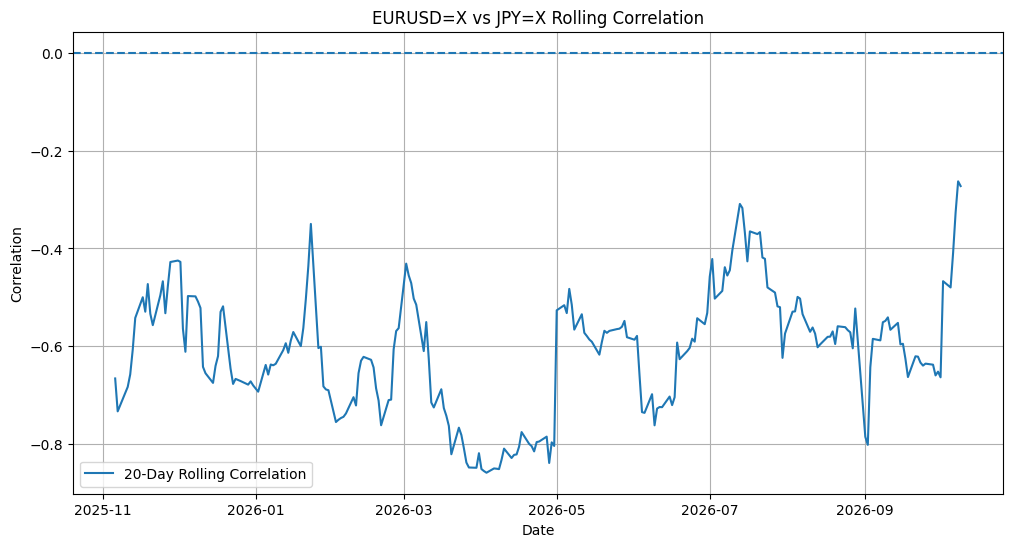

In [ ]:
# how well these two deriviatives move

correlation = derivative1["Returns"].corr(derivative2["Returns"])

returns = pd.concat(
    [
        derivative1["Returns"],
        derivative2["Returns"]
    ],
    axis=1
).dropna()


# 20-day rolling correlation
returns["Rolling Corr"] = (
    returns.iloc[:, 0]
    .rolling(20)
    .corr(returns.iloc[:, 1]))

print(f"current correlation (Full Period): {correlation}")
print(
    "Current 20-day correlation:",
    returns["Rolling Corr"].iloc[-1]
)

# Plot
plt.figure(figsize=(12, 6))

plt.plot(
    returns.index,
    returns["Rolling Corr"],
    label="20-Day Rolling Correlation"
)

plt.axhline(0, linestyle="--")

plt.title(
    f"{commoditie1} vs {commoditie2} Rolling Correlation"
)

plt.xlabel("Date")
plt.ylabel("Correlation")

plt.legend()
plt.grid(True)

plt.show()

In [ ]:
#coinintergration test

#p < 0.05 → evidence that the two price series are cointegrated
#p >= 0.05 → not enough evidence to conclude they are cointegrated

#Do these two assets have a stable enough long-term relationship
#that it makes sense to trade their temporary divergences?
#sell the over performer and buy the under performer

prices = pd.concat(
    [
        derivative1["Close"],
        derivative2["Close"]
    ],
    axis=1
).dropna()


# Cointegration test
score, p_value, critical_values = coint(
    prices.iloc[:, 0],
    prices.iloc[:, 1]
)

print("Cointegration p-value:", p_value)

Cointegration p-value: 0.8582371973887319


Cointegration p-value: 0.8582371973887319
Alpha: 1.5436238224975312
Beta: -0.0024294680565608772

Latest Spread: -0.03600961578838513
Latest Z-Score: -1.279311834347537
Spread is somewhat away from its recent average.


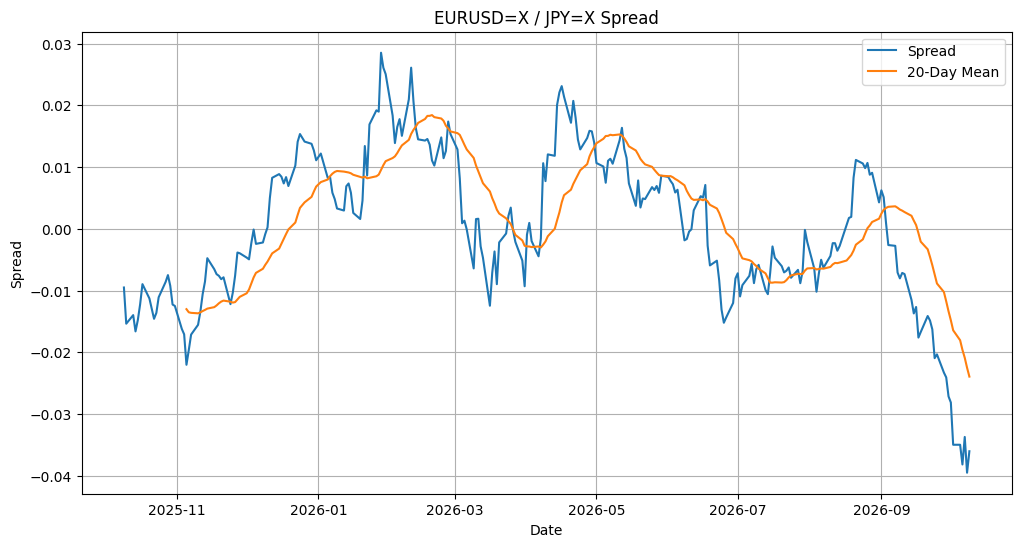

In [ ]:
# Combine and remove missing dates
# -----------------------------
# 1. Combine close prices
# -----------------------------
prices = pd.concat(
    [
        derivative1["Close"],
        derivative2["Close"]
    ],
    axis=1
).dropna()


# -----------------------------
# 2. Cointegration test
# -----------------------------
score, p_value, critical_values = coint(
    prices.iloc[:, 0],
    prices.iloc[:, 1]
)

print("Cointegration p-value:", p_value)


# -----------------------------
# 3. Estimate hedge ratio
# Asset 1 = alpha + beta * Asset 2
# -----------------------------
X = sm.add_constant(prices.iloc[:, 1])

model = sm.OLS(
    prices.iloc[:, 0],
    X
).fit()

alpha = model.params.iloc[0]
beta = model.params.iloc[1]

print("Alpha:", alpha)
print("Beta:", beta)


# -----------------------------
# 4. Calculate spread
# -----------------------------
prices["Spread"] = (
    prices.iloc[:, 0]
    - alpha
    - beta * prices.iloc[:, 1]
)


# -----------------------------
# 5. Calculate rolling z-score
# -----------------------------
window = 20

prices["Spread Mean"] = (
    prices["Spread"]
    .rolling(window)
    .mean()
)

prices["Spread Std"] = (
    prices["Spread"]
    .rolling(window)
    .std()
)

prices["Z-Score"] = (
    prices["Spread"] - prices["Spread Mean"]
) / prices["Spread Std"]


# -----------------------------
# 6. Latest values
# -----------------------------
latest_spread = prices["Spread"].iloc[-1]
latest_zscore = prices["Z-Score"].iloc[-1]

print("\nLatest Spread:", latest_spread)
print("Latest Z-Score:", latest_zscore)


# -----------------------------
# 7. Interpret z-score
# -----------------------------
if latest_zscore > 2:
    print("Spread is unusually HIGH.")

elif latest_zscore < -2:
    print("Spread is unusually LOW.")

elif -1 <= latest_zscore <= 1:
    print("Spread is relatively NORMAL.")

else:
    print("Spread is somewhat away from its recent average.")


# -----------------------------
# 8. Plot spread
# -----------------------------
plt.figure(figsize=(12, 6))

plt.plot(
    prices.index,
    prices["Spread"],
    label="Spread"
)

plt.plot(
    prices.index,
    prices["Spread Mean"],
    label="20-Day Mean"
)

plt.title(
    f"{commoditie1} / {commoditie2} Spread"
)

plt.xlabel("Date")
plt.ylabel("Spread")
plt.legend()
plt.grid(True)

plt.show()


#BETA(x): a $1 change in derivative2 is associated with about a $x change
#in the fitted deriviatve1 price.

#Latest-Spread(X):derivative1 is currently about $X below/above the price implied
# by that fitted derivative1/derivative2 relationship:

#ZSCORE(x): X standard deviations below its recent 20-day average

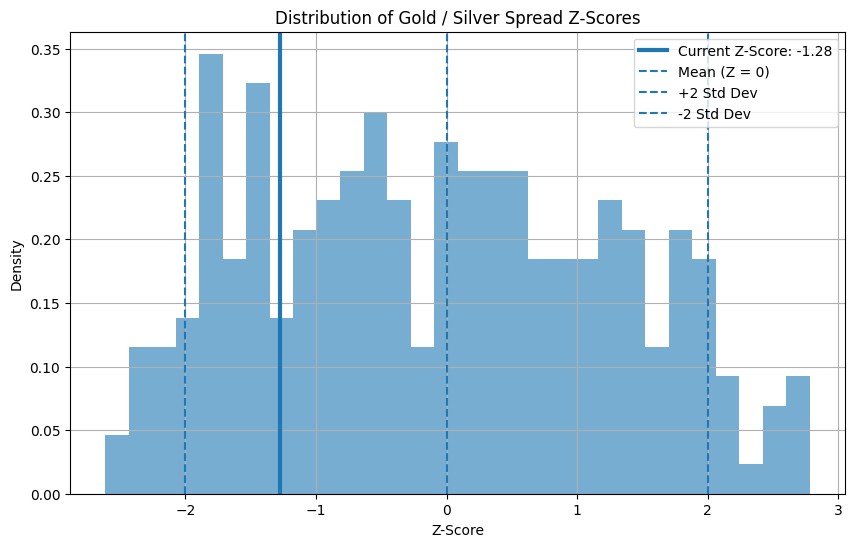

In [ ]:
#distrobution score

# Remove NaN values from the rolling calculation
z_scores = prices["Z-Score"].dropna()

latest_zscore = z_scores.iloc[-1]

plt.figure(figsize=(10, 6))

# Distribution of historical z-scores
plt.hist(
    z_scores,
    bins=30,
    density=True,
    alpha=0.6
)

# Current/latest z-score
plt.axvline(
    latest_zscore,
    linewidth=3,
    label=f"Current Z-Score: {latest_zscore:.2f}"
)

# Mean
plt.axvline(
    0,
    linestyle="--",
    label="Mean (Z = 0)"
)

# Common outlier thresholds
plt.axvline(2, linestyle="--", label="+2 Std Dev")
plt.axvline(-2, linestyle="--", label="-2 Std Dev")

plt.title("Distribution of Gold / Silver Spread Z-Scores")
plt.xlabel("Z-Score")
plt.ylabel("Density")

plt.legend()
plt.grid(True)

plt.show()

if we go 0.1 lots on one asset

and hedge ratio is .80

then on the second asset we would use .1 * .80

0.08 lots on the second asset

In [ ]:
# ROLLING HEDGE RATIO

window = 20

asset1 = returns.iloc[:, 0].copy()
asset2 = returns.iloc[:, 1].copy()

# Convert percent returns to decimals if needed
if asset1.abs().mean() > 1:
    asset1 = asset1 / 100
    asset2 = asset2 / 100

# Rolling correlation
rolling_corr = (
    asset1
    .rolling(window)
    .corr(asset2)
)

# Rolling volatility
rolling_vol1 = asset1.rolling(window).std()
rolling_vol2 = asset2.rolling(window).std()

# Rolling hedge ratio
rolling_hedge_ratio = (
    -rolling_corr *
    (rolling_vol1 / rolling_vol2)
)

# Dynamic weights
weight1 = 1 / (1 + rolling_hedge_ratio.abs())

weight2 = (
    rolling_hedge_ratio /
    (1 + rolling_hedge_ratio.abs())
)

# Save into dataframe
returns["Rolling Corr"] = rolling_corr
returns["Rolling Vol 1"] = rolling_vol1
returns["Rolling Vol 2"] = rolling_vol2
returns["Hedge Ratio"] = rolling_hedge_ratio
returns["Weight 1"] = weight1
returns["Weight 2"] = weight2

# Dynamic strategy return
returns["Strategy Return"] = (
    returns["Weight 1"] * asset1
    + returns["Weight 2"] * asset2
)

print("Current Correlation:", returns["Rolling Corr"].iloc[-1])
print("Current Hedge Ratio:", returns["Hedge Ratio"].iloc[-1])
print("Current Asset 1 Weight:", returns["Weight 1"].iloc[-1])
print("Current Asset 2 Weight:", returns["Weight 2"].iloc[-1])

Current Correlation: -0.27254968163508664
Current Hedge Ratio: 0.1964022657906744
Current Asset 1 Weight: 0.8358392729548396
Current Asset 2 Weight: 0.16416072704516046


In [ ]:
# FRACTIONAL KELLY

account_capital = 100
kelly_fraction = 0.25

mean_return = strategy_returns.mean()
variance = strategy_returns.var()

full_kelly = mean_return / variance

fractional_kelly = full_kelly * kelly_fraction

# Keep allocation between 0% and 100%
fractional_kelly = max(0, min(fractional_kelly, 1))

capital_allocated = account_capital * fractional_kelly

asset1_capital = capital_allocated * abs(weight1)
asset2_capital = capital_allocated * abs(weight2)

print("Full Kelly:", full_kelly)
print("Fractional Kelly:", fractional_kelly)
print("Capital Allocated:", capital_allocated)
print("Asset 1 Capital:", asset1_capital)
print("Asset 2 Capital:", asset2_capital)

Full Kelly: -0.2075465959661733
Fractional Kelly: 0
Capital Allocated: 0
Asset 1 Capital: Date
2025-10-07    NaN
2025-10-08    NaN
2025-10-09    NaN
2025-10-10    NaN
2025-10-13    NaN
             ... 
2026-09-30    0.0
2026-10-01    0.0
2026-10-02    0.0
2026-10-05    0.0
2026-10-06    0.0
Name: Returns, Length: 259, dtype: float64
Asset 2 Capital: Date
2025-10-07    NaN
2025-10-08    NaN
2025-10-09    NaN
2025-10-10    NaN
2025-10-13    NaN
             ... 
2026-09-30    0.0
2026-10-01    0.0
2026-10-02    0.0
2026-10-05    0.0
2026-10-06    0.0
Name: Returns, Length: 259, dtype: float64
